# Упражнение 2.1: чтение изображения и интенсивность RGB

Задача: считать изображение через OpenCV, определить разрешение и найти значения каналов `R`, `G`, `B` для пикселя на пересечении строки `2428` и столбца `3688`.

## 1. Импорты и путь к изображению

Изображение скачано из задания в папку `input_images`.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt

IMAGE_PATH = Path('input_images/alex-blajan-FlUbZ-2S014-unsplash.jpg')
if not IMAGE_PATH.exists():
    raise FileNotFoundError(f'Не найден файл: {IMAGE_PATH}')

IMAGE_PATH

PosixPath('input_images/alex-blajan-FlUbZ-2S014-unsplash.jpg')

## 2. Чтение изображения через OpenCV

`cv2.imread()` читает цветное изображение в формате каналов `BGR`, а не `RGB`.

In [2]:
image_bgr = cv2.imread(str(IMAGE_PATH), cv2.IMREAD_COLOR)
if image_bgr is None:
    raise ValueError('OpenCV не смог считать изображение')

height, width, channels = image_bgr.shape
print(f'Ширина: {width} px')
print(f'Высота: {height} px')
print(f'Количество каналов: {channels}')

Ширина: 7360 px
Высота: 4912 px
Количество каналов: 3


## 3. Значения каналов в заданном пикселе

В матричном представлении OpenCV обращение идет как `image[row, col]`, то есть сначала строка, потом столбец. Значение `image_bgr[2428, 3688]` возвращает каналы в порядке `B, G, R`, поэтому ниже они переставлены в `R, G, B`.

In [3]:
row = 2428
col = 3688

b, g, r = image_bgr[row, col].tolist()

print(f'BGR для image_bgr[{row}, {col}]: B={b}, G={g}, R={r}')
print(f'RGB: R={r}, G={g}, B={b}')

BGR для image_bgr[2428, 3688]: B=92, G=62, R=165
RGB: R=165, G=62, B=92


## 4. Визуальная проверка точки

На полном изображении точка почти не видна, поэтому показан небольшой фрагмент вокруг нужного пикселя.

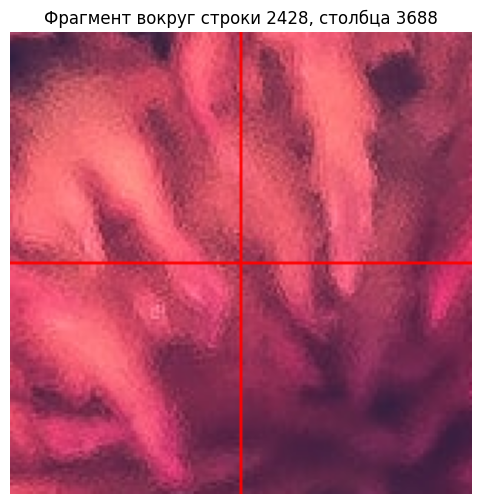

In [4]:
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

radius = 80
crop = image_rgb[row-radius:row+radius+1, col-radius:col+radius+1].copy()
center = radius

# Красный крест отмечает проверяемый пиксель на увеличенном фрагменте.
crop[center, :, :] = [255, 0, 0]
crop[:, center, :] = [255, 0, 0]

plt.figure(figsize=(6, 6))
plt.imshow(crop)
plt.title(f'Фрагмент вокруг строки {row}, столбца {col}')
plt.axis('off')
plt.show()

## Ответы для формы

- Ширина изображения: `7360`
- Высота изображения: `4912`
- Канал R: `165`
- Канал G: `62`
- Канал B: `92`